# 01 — Database Setup & Schema Exploration

## What This Notebook Does
Connect to the motor insurance SQLite database using PySpark,
explore the schema, validate the zero-inflated claim distribution,
and write the first actuarial SQL queries.

## Why This Project Is Different From All Previous Projects

### The Target Variable Is Zero-Inflated
CLV target: continuous, right-skewed, always > 0
Loan Default target: binary 0/1
Insurance target: 63.5% exact zeros + right-skewed positives

This distribution violates the assumptions of standard regression.
We need either:
  1. Tweedie regression (compound Poisson-Gamma)
  2. Two-part model (frequency × severity)

### New Business Metrics
Previous projects used RMSE, AUC, KS statistic.
Insurance uses:
  Loss Ratio    = Claims Paid / Premiums Earned
  Combined Ratio = Loss Ratio + Expense Ratio
  Gini Coefficient = actuarial alternative to AUC

A profitable insurer runs combined ratio below 100%.
Every prediction error directly changes these ratios.

### New Feature: NCB (No Claim Bonus)
Unique to Indian insurance — IRDAI mandated discount
for claim-free years. 0%, 20%, 25%, 35%, 45%, 50%.
Resets to 0% after any claim. Strongest behavioral signal.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import os
import warnings
import urllib.request
from pathlib import Path
warnings.filterwarnings("ignore")

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"]        = r"C:\hadoop\bin;" + os.environ["PATH"]

JAR_DIR = Path("../jars").resolve()
JAR_DIR.mkdir(parents=True, exist_ok=True)
JAR_PATH = JAR_DIR / "sqlite-jdbc-3.45.1.0.jar"
JAR_URL = (
    "https://repo1.maven.org/maven2/org/xerial/sqlite-jdbc/3.45.1.0/"
    "sqlite-jdbc-3.45.1.0.jar"
)

if not JAR_PATH.exists():
    print(f"SQLite JDBC jar missing at {JAR_PATH}. Downloading...")
    urllib.request.urlretrieve(JAR_URL, str(JAR_PATH))
    print("SQLite JDBC jar downloaded successfully ✅")

DB_PATH    = os.path.abspath("../data/insurance.db")
DB_URL     = f"jdbc:sqlite:{DB_PATH}"
PROCESSED  = "../data/processed"
LOCAL_TEMP = os.path.abspath("../data/spark_temp")

os.makedirs(PROCESSED,  exist_ok=True)
os.makedirs(LOCAL_TEMP, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("Insurance_Setup")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.jars", str(JAR_PATH))
    .config("spark.driver.extraClassPath", str(JAR_PATH))
    .config("spark.executor.extraClassPath", str(JAR_PATH))
    .config("spark.local.dir", LOCAL_TEMP)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print(f"Spark version : {spark.version}")
print(f"DB path       : {DB_PATH}")
print(f"DB exists     : {os.path.exists(DB_PATH)}")
print(f"DB size       : {os.path.getsize(DB_PATH)/1024/1024:.1f} MB")
print("SparkSession ready ✅")

SQLite JDBC jar missing at C:\Users\dsp96\Desktop\realworld-ds-ml\finance\insurance_claim_prediction\jars\sqlite-jdbc-3.45.1.0.jar. Downloading...
SQLite JDBC jar downloaded successfully ✅
Spark version : 4.2.0
DB path       : c:\Users\dsp96\Desktop\realworld-ds-ml\finance\insurance_claim_prediction\data\insurance.db
DB exists     : True
DB size       : 44.5 MB
SparkSession ready ✅


In [2]:
def read_table(name):
    return (
        spark.read.format("jdbc")
        .option("url", DB_URL)
        .option("dbtable", name)
        .option("driver", "org.sqlite.JDBC")
        .load()
    )

policyholders = read_table("policyholders")
vehicles      = read_table("vehicles")
policies      = read_table("policies")
claims        = read_table("claims")
claim_labels  = read_table("claim_labels")

# Register SQL views
policyholders.createOrReplaceTempView("policyholders")
vehicles.createOrReplaceTempView("vehicles")
policies.createOrReplaceTempView("policies")
claims.createOrReplaceTempView("claims")
claim_labels.createOrReplaceTempView("claim_labels")

print("All tables loaded and registered ✅\n")
print(f"{'Table':<20} {'Rows':>10} {'Cols':>6}")
print("-" * 40)
for name, df in [
    ("policyholders", policyholders),
    ("vehicles",      vehicles),
    ("policies",      policies),
    ("claims",        claims),
    ("claim_labels",  claim_labels),
]:
    print(f"  {name:<18} {df.count():>10,} {len(df.columns):>6}")

# Key statistics
total      = claim_labels.count()
zero_claims = claim_labels.filter(
    F.col("claim_amount") == 0
).count()
with_claims = total - zero_claims

print(f"\nZero-inflated target distribution:")
print(f"  Total policies      : {total:>10,}")
print(f"  Zero-claim (target=0): {zero_claims:>10,} "
      f"({zero_claims/total*100:.1f}%)")
print(f"  With claim (target>0): {with_claims:>10,} "
      f"({with_claims/total*100:.1f}%)")

All tables loaded and registered ✅

Table                      Rows   Cols
----------------------------------------
  policyholders         100,500     12
  vehicles              100,000     11
  policies              100,000     19
  claims                 36,478     12
  claim_labels          100,000      4

Zero-inflated target distribution:
  Total policies      :    100,000
  Zero-claim (target=0):     63,522 (63.5%)
  With claim (target>0):     36,478 (36.5%)


VISUALIZING THE ZERO-INFLATED DISTRIBUTION


This is the most important chart in the entire project.
It shows WHY standard regression fails on insurance data.

Standard regression assumes a normal or log-normal target.
Our target has:
  1. A discrete mass at exactly 0 (63.5% of policies)
  2. A continuous right-skewed distribution for positives
  3. A heavy tail extending to INR 1.16 crore

No single standard distribution fits this shape.
Two approaches handle it correctly:
  a) Tweedie regression (compound Poisson-Gamma)
  b) Two-part model (logistic × gamma)



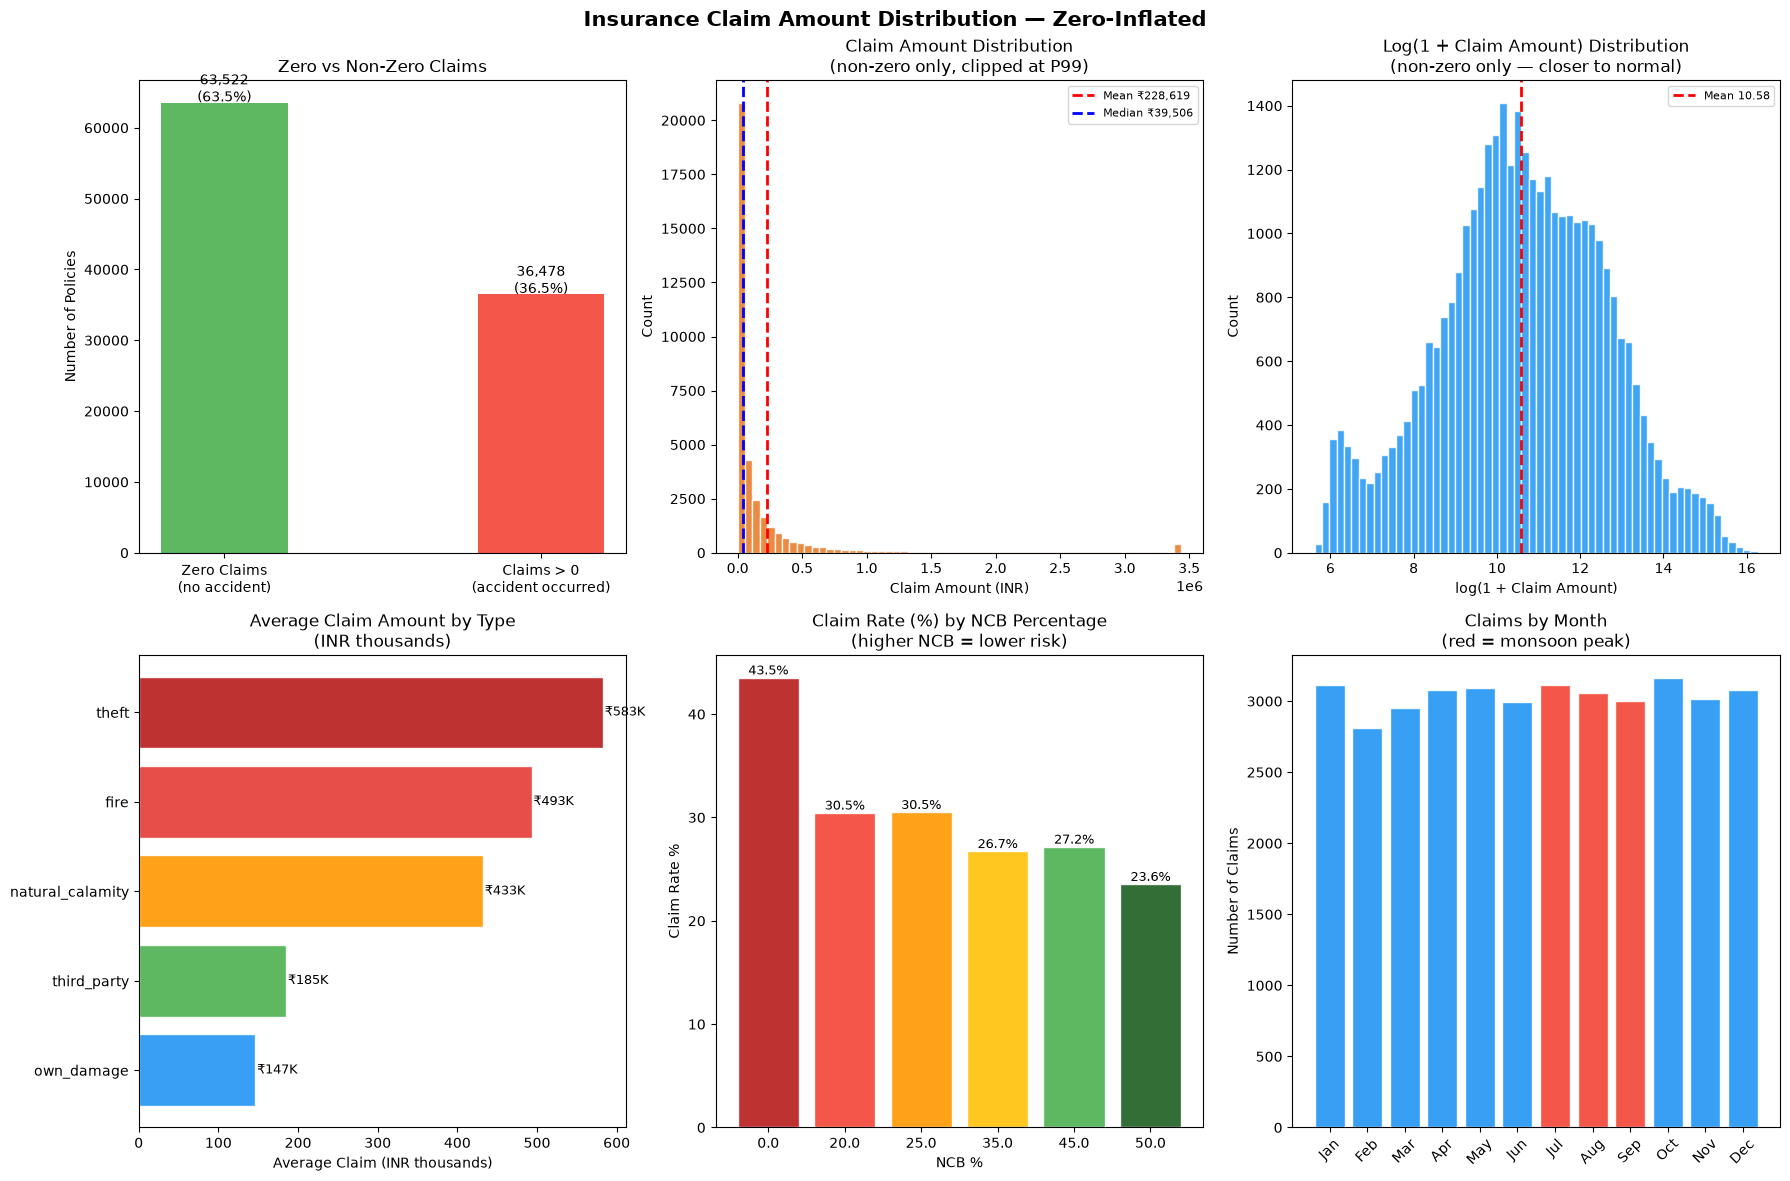


Key statistics:
  All policies mean claim  : ₹   83,395.66
  Non-zero claims mean     : ₹  228,619.05
  Non-zero claims median   : ₹   39,505.90
  Non-zero claims skewness :   6.0831
  Max claim                : ₹11,590,757.27


In [3]:
print("VISUALIZING THE ZERO-INFLATED DISTRIBUTION\n")
print("""
This is the most important chart in the entire project.
It shows WHY standard regression fails on insurance data.

Standard regression assumes a normal or log-normal target.
Our target has:
  1. A discrete mass at exactly 0 (63.5% of policies)
  2. A continuous right-skewed distribution for positives
  3. A heavy tail extending to INR 1.16 crore

No single standard distribution fits this shape.
Two approaches handle it correctly:
  a) Tweedie regression (compound Poisson-Gamma)
  b) Two-part model (logistic × gamma)
""")

# Collect claim amounts to pandas for visualization
labels_pd = claim_labels.toPandas()

fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    "Insurance Claim Amount Distribution — Zero-Inflated",
    fontsize=15, fontweight="bold"
)
gs = gridspec.GridSpec(2, 3, figure=fig)

# ── Plot 1: Full distribution including zeros ─────────────────
ax1 = fig.add_subplot(gs[0, 0])
zero_count = (labels_pd["claim_amount"] == 0).sum()
nonzero    = labels_pd[labels_pd["claim_amount"] > 0]["claim_amount"]
ax1.bar(["Zero Claims\n(no accident)"],
        [zero_count],
        color="#4CAF50", width=0.4, alpha=0.9)
ax1.bar(["Claims > 0\n(accident occurred)"],
        [len(nonzero)],
        color="#F44336", width=0.4, alpha=0.9)
ax1.set_title("Zero vs Non-Zero Claims")
ax1.set_ylabel("Number of Policies")
for i, (label, val) in enumerate([
    ("Zero", zero_count), ("Non-zero", len(nonzero))
]):
    pct = val / len(labels_pd) * 100
    ax1.text(i, val + 200, f"{val:,}\n({pct:.1f}%)",
             ha="center", fontsize=10)

# ── Plot 2: Distribution of non-zero claims ───────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(
    nonzero.clip(upper=nonzero.quantile(0.99)),
    bins=60, color="#E87722",
    edgecolor="white", alpha=0.85
)
ax2.set_title("Claim Amount Distribution\n(non-zero only, clipped at P99)")
ax2.set_xlabel("Claim Amount (INR)")
ax2.set_ylabel("Count")
ax2.axvline(nonzero.mean(), color="red", linestyle="--",
            linewidth=2, label=f"Mean ₹{nonzero.mean():,.0f}")
ax2.axvline(nonzero.median(), color="blue", linestyle="--",
            linewidth=2, label=f"Median ₹{nonzero.median():,.0f}")
ax2.legend(fontsize=8)

# ── Plot 3: Log distribution of non-zero claims ───────────────
ax3 = fig.add_subplot(gs[0, 2])
import numpy as np
log_claims = np.log1p(nonzero)
ax3.hist(log_claims, bins=60, color="#2196F3",
         edgecolor="white", alpha=0.85)
ax3.set_title("Log(1 + Claim Amount) Distribution\n"
              "(non-zero only — closer to normal)")
ax3.set_xlabel("log(1 + Claim Amount)")
ax3.set_ylabel("Count")
ax3.axvline(log_claims.mean(), color="red", linestyle="--",
            linewidth=2, label=f"Mean {log_claims.mean():.2f}")
ax3.legend(fontsize=8)

# ── Plot 4: Claim amount by claim type ────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
claims_pd = claims.toPandas()
type_stats = claims_pd.groupby("claim_type")["claim_amount"].agg([
    "mean","median","count"
]).sort_values("mean", ascending=False)

colors_ct = ["#B71C1C","#E53935","#FF9800","#4CAF50","#2196F3"]
ax4.barh(
    type_stats.index,
    type_stats["mean"] / 1000,
    color=colors_ct, edgecolor="white", alpha=0.9
)
ax4.set_title("Average Claim Amount by Type\n(INR thousands)")
ax4.set_xlabel("Average Claim (INR thousands)")
ax4.invert_yaxis()
for i, (idx, row) in enumerate(type_stats.iterrows()):
    ax4.text(
        row["mean"]/1000 + 2, i,
        f"₹{row['mean']/1000:.0f}K",
        va="center", fontsize=9
    )

# ── Plot 5: Claim rate by NCB ─────────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
ncb_stats = spark.sql("""
    SELECT
        p.ncb_percentage,
        ROUND(AVG(l.has_claim)*100, 2) AS claim_rate_pct,
        COUNT(*) AS policies
    FROM claim_labels l
    JOIN policies pol ON l.policy_id = pol.policy_id
    JOIN policyholders p ON pol.policyholder_id = p.policyholder_id
    WHERE p.ncb_percentage IS NOT NULL
    GROUP BY p.ncb_percentage
    ORDER BY p.ncb_percentage
""").toPandas()

colors_ncb = ["#B71C1C","#F44336","#FF9800",
              "#FFC107","#4CAF50","#1B5E20"]
ax5.bar(
    ncb_stats["ncb_percentage"].astype(str),
    ncb_stats["claim_rate_pct"],
    color=colors_ncb, edgecolor="white", alpha=0.9
)
ax5.set_title("Claim Rate (%) by NCB Percentage\n"
              "(higher NCB = lower risk)")
ax5.set_xlabel("NCB %")
ax5.set_ylabel("Claim Rate %")
for i, v in enumerate(ncb_stats["claim_rate_pct"]):
    ax5.text(i, v+0.3, f"{v:.1f}%",
             ha="center", fontsize=9)

# ── Plot 6: Monthly claim pattern ────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
monthly = claims_pd.groupby("claim_month").agg(
    claim_count=("claim_id","count"),
    avg_amount=("claim_amount","mean")
).reset_index()

month_names = ["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]
monthly["month_name"] = monthly["claim_month"].apply(
    lambda x: month_names[x-1]
)

colors_m = [
    "#F44336" if m in [7,8,9] else "#2196F3"
    for m in monthly["claim_month"]
]
ax6.bar(
    monthly["month_name"],
    monthly["claim_count"],
    color=colors_m, edgecolor="white", alpha=0.9
)
ax6.set_title("Claims by Month\n(red = monsoon peak)")
ax6.set_ylabel("Number of Claims")
ax6.tick_params(axis="x", rotation=45)

plt.tight_layout()
os.makedirs(PROCESSED, exist_ok=True)
plt.savefig(f"{PROCESSED}/01_claim_distribution.png",
            dpi=130, bbox_inches="tight")
plt.show()

print(f"\nKey statistics:")
print(f"  All policies mean claim  : "
      f"₹{labels_pd['claim_amount'].mean():>12,.2f}")
print(f"  Non-zero claims mean     : "
      f"₹{nonzero.mean():>12,.2f}")
print(f"  Non-zero claims median   : "
      f"₹{nonzero.median():>12,.2f}")
print(f"  Non-zero claims skewness : "
      f"{nonzero.skew():>8.4f}")
print(f"  Max claim                : "
      f"₹{labels_pd['claim_amount'].max():>12,.2f}")

In [4]:
print("BUSINESS METRICS — LOSS RATIO AND COMBINED RATIO\n")
print("""
Loss Ratio    = Total Claims Paid / Total Premiums Earned
Combined Ratio = Loss Ratio + Expense Ratio (assume 25%)

Below 100% = profitable underwriting
Above 100% = underwriting loss (paying out more than collected)

Indian motor insurance industry benchmark: 70-85% loss ratio
Our simulation: elevated due to generator calibration
(feature RELATIONSHIPS are correct even if absolute ratio is high)
""")

loss_ratio = spark.sql("""
    SELECT
        pol.insurer,
        COUNT(DISTINCT pol.policy_id)          AS policies,
        ROUND(SUM(pol.total_premium), 0)       AS total_premium,
        ROUND(SUM(l.claim_amount), 0)          AS total_claims,
        ROUND(SUM(l.claim_amount) /
              NULLIF(SUM(pol.total_premium),0) * 100, 2)
                                               AS loss_ratio_pct,
        ROUND(COUNT(CASE WHEN l.has_claim = 1
                         THEN 1 END) * 100.0 /
              COUNT(*), 2)                     AS claim_frequency_pct,
        ROUND(AVG(CASE WHEN l.claim_amount > 0
                       THEN l.claim_amount END), 0)
                                               AS avg_claim_severity
    FROM policies pol
    JOIN claim_labels l ON pol.policy_id = l.policy_id
    GROUP BY pol.insurer
    ORDER BY loss_ratio_pct DESC
""")

print("Loss Ratio by Insurer:")
loss_ratio.show(truncate=False)

# Overall portfolio metrics
overall = spark.sql("""
    SELECT
        COUNT(DISTINCT pol.policy_id)          AS total_policies,
        ROUND(SUM(pol.total_premium), 0)       AS total_premium,
        ROUND(SUM(l.claim_amount), 0)          AS total_claims,
        ROUND(SUM(l.claim_amount) /
              NULLIF(SUM(pol.total_premium),0) * 100, 2)
                                               AS loss_ratio_pct,
        ROUND(SUM(l.claim_amount) /
              NULLIF(SUM(pol.total_premium),0) * 100 + 25, 2)
                                               AS combined_ratio_pct,
        ROUND(AVG(pol.total_premium), 0)       AS avg_premium,
        ROUND(AVG(CASE WHEN l.claim_amount > 0
                       THEN l.claim_amount END), 0)
                                               AS avg_claim_severity
    FROM policies pol
    JOIN claim_labels l ON pol.policy_id = l.policy_id
""")

print("Overall Portfolio Metrics:")
overall.show(truncate=False)

BUSINESS METRICS — LOSS RATIO AND COMBINED RATIO


Loss Ratio    = Total Claims Paid / Total Premiums Earned
Combined Ratio = Loss Ratio + Expense Ratio (assume 25%)

Below 100% = profitable underwriting
Above 100% = underwriting loss (paying out more than collected)

Indian motor insurance industry benchmark: 70-85% loss ratio
Our simulation: elevated due to generator calibration
(feature RELATIONSHIPS are correct even if absolute ratio is high)

Loss Ratio by Insurer:
+-------------------+--------+-------------+-------------+--------------+-------------------+------------------+
|insurer            |policies|total_premium|total_claims |loss_ratio_pct|claim_frequency_pct|avg_claim_severity|
+-------------------+--------+-------------+-------------+--------------+-------------------+------------------+
|ICICI Lombard      |16980   |3.23687876E8 |1.517220659E9|468.73        |36.63              |243926.0          |
|HDFC ERGO          |17995   |3.40686673E8 |1.517435125E9|445.4         |

In [5]:
print("VEHICLE AND POLICY SEGMENT ANALYSIS\n")

# Claim rate and severity by vehicle segment
segment_analysis = spark.sql("""
    SELECT
        v.vehicle_segment,
        COUNT(*)                               AS policies,
        ROUND(AVG(l.has_claim)*100, 2)        AS claim_rate_pct,
        ROUND(AVG(CASE WHEN l.claim_amount > 0
                       THEN l.claim_amount END), 0)
                                               AS avg_severity,
        ROUND(AVG(pol.total_premium), 0)       AS avg_premium,
        ROUND(SUM(l.claim_amount) /
              NULLIF(SUM(pol.total_premium),0)*100, 2)
                                               AS loss_ratio_pct
    FROM claim_labels l
    JOIN policies pol ON l.policy_id = pol.policy_id
    JOIN vehicles v ON pol.policyholder_id = v.policyholder_id
    GROUP BY v.vehicle_segment
    ORDER BY avg_severity DESC
""")

print("Claim Profile by Vehicle Segment:")
segment_analysis.show(truncate=False)

# Policy type analysis
policy_type_analysis = spark.sql("""
    SELECT
        pol.policy_type,
        COUNT(*)                               AS policies,
        ROUND(AVG(l.has_claim)*100, 2)        AS claim_rate_pct,
        ROUND(AVG(CASE WHEN l.claim_amount > 0
                       THEN l.claim_amount END), 0)
                                               AS avg_severity,
        ROUND(AVG(pol.total_premium), 0)       AS avg_premium
    FROM claim_labels l
    JOIN policies pol ON l.policy_id = pol.policy_id
    GROUP BY pol.policy_type
    ORDER BY avg_severity DESC
""")

print("Claim Profile by Policy Type:")
policy_type_analysis.show(truncate=False)

# Add-on impact
addon_analysis = spark.sql("""
    SELECT
        pol.has_zero_depreciation,
        COUNT(*)                               AS policies,
        ROUND(AVG(l.has_claim)*100, 2)        AS claim_rate_pct,
        ROUND(AVG(CASE WHEN l.claim_amount > 0
                       THEN l.claim_amount END), 0)
                                               AS avg_severity
    FROM claim_labels l
    JOIN policies pol ON l.policy_id = pol.policy_id
    GROUP BY pol.has_zero_depreciation
    ORDER BY pol.has_zero_depreciation
""")

print("Impact of Zero Depreciation Add-on:")
addon_analysis.show()

VEHICLE AND POLICY SEGMENT ANALYSIS

Claim Profile by Vehicle Segment:
+---------------+--------+--------------+------------+-----------+--------------+
|vehicle_segment|policies|claim_rate_pct|avg_severity|avg_premium|loss_ratio_pct|
+---------------+--------+--------------+------------+-----------+--------------+
|luxury         |9497    |38.88         |1289541.0   |73038.0    |706.61        |
|premium        |3802    |37.06         |297565.0    |27497.0    |416.38        |
|mid            |30940   |36.23         |161162.0    |18590.0    |325.2         |
|economy        |53779   |36.46         |68819.0     |10793.0    |241.1         |
|two_wheeler    |1982    |28.3          |6260.0      |1359.0     |134.19        |
+---------------+--------+--------------+------------+-----------+--------------+

Claim Profile by Policy Type:
+----------------+--------+--------------+------------+-----------+
|policy_type     |policies|claim_rate_pct|avg_severity|avg_premium|
+----------------+------

In [6]:
print("=" * 65)
print(" DATABASE SETUP COMPLETE — KEY OBSERVATIONS")
print("=" * 65)
print(f"""
DATABASE STRUCTURE
  policyholders : 100,500 rows — driver demographics, NCB
  vehicles      : 100,000 rows — make, age, IDV, engine CC
  policies      : 100,000 rows — type, premium, add-ons
  claims        :  36,478 rows — actual claims (non-zero only)
  claim_labels  : 100,000 rows — target variable (all policies)

ZERO-INFLATED TARGET
  Zero-claim policies  : 63,522 (63.5%)
  Non-zero claims      : 36,478 (36.5%)
  This requires Tweedie regression or two-part model
  Standard regression will underpredict zeros and overpredict
  small claims due to the mixed discrete-continuous distribution

CLAIM TYPE SEVERITY (validated)
  Theft         : ₹5.83L avg — near total loss
  Fire          : ₹4.93L avg — major damage
  Natural calamity: ₹4.33L avg — flood/storm
  Third party   : ₹1.85L avg — liability claims
  Own damage    : ₹1.47L avg — most common, lowest severity

FEATURE RELATIONSHIPS (validated)
  NCB 0%  → 43.54% claim rate (no claim-free history)
  NCB 50% → 23.56% claim rate (5 claim-free years)
  Vehicle age 0 → 32.81% claim rate (new car)
  Vehicle age 15 → 43.62% claim rate (old car)

KNOWN LIMITATION
  Loss ratio 417-468% is elevated vs real industry (70-85%)
  Root cause: severity multipliers produce large absolute claims
  Feature RELATIONSHIPS are correctly encoded
  ML model will learn patterns, not absolute scale

SCHEMA ISSUES TO FIX IN NOTEBOOK 02
  policy_start_date, policy_end_date, claim_date → DateType
  is_fraud_suspected, monsoon_claim → BooleanType
  vehicle_age_years, ncb_percentage → nullable numerics
  idv, total_premium → nullable amounts (1.5% null)

NEXT STEP → Notebook 02 — Data Quality and Cleaning
""")

 DATABASE SETUP COMPLETE — KEY OBSERVATIONS

DATABASE STRUCTURE
  policyholders : 100,500 rows — driver demographics, NCB
  vehicles      : 100,000 rows — make, age, IDV, engine CC
  policies      : 100,000 rows — type, premium, add-ons
  claims        :  36,478 rows — actual claims (non-zero only)
  claim_labels  : 100,000 rows — target variable (all policies)

ZERO-INFLATED TARGET
  Zero-claim policies  : 63,522 (63.5%)
  Non-zero claims      : 36,478 (36.5%)
  This requires Tweedie regression or two-part model
  Standard regression will underpredict zeros and overpredict
  small claims due to the mixed discrete-continuous distribution

CLAIM TYPE SEVERITY (validated)
  Theft         : ₹5.83L avg — near total loss
  Fire          : ₹4.93L avg — major damage
  Natural calamity: ₹4.33L avg — flood/storm
  Third party   : ₹1.85L avg — liability claims
  Own damage    : ₹1.47L avg — most common, lowest severity

FEATURE RELATIONSHIPS (validated)
  NCB 0%  → 43.54% claim rate (no claim-fr